In [7]:
# Setup: imports, global random seed, display options and package versions for reproducibility
import os
import re
import sys
import glob
import random
import zipfile
import subprocess
import unicodedata
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import chi2_contingency, ks_2samp

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

print("python    ", sys.version.split()[0])
for lib in (np, pd, matplotlib, sns, scipy):
    print(f"{lib.__name__:<10}", lib.__version__)

python     3.13.18
numpy      2.4.6
pandas     2.2.3
matplotlib 3.10.0
seaborn    0.13.2
scipy      1.16.3


## Data acquisition with a Kaggle API token

The next cell looks for the official competition files in this order and uses the first match:

1. **Kaggle notebook**: the files are already attached under `/kaggle/input/contradictory-my-dear-watson`, so no token is needed (this is how the final submission notebook runs).
2. **Local `data/` folder** next to the notebook.
3. **Download with the Kaggle API**: used in Colab. Steps 1 to 3 below are a one-time setup.

**One-time setup for Colab**

1. On kaggle.com, open the competition page and accept the rules (**Join Competition** / **Late Submission**). Without this the download fails with `403 Forbidden`.
2. Go to Kaggle → **Settings** → **API** → **Create New Token** and copy the token (it starts with `KGAT_`).
3. In Colab, open the **key icon** (Secrets) in the left sidebar, add a secret named `KAGGLE_API_TOKEN` with the token as its value, and turn on **Notebook access**.

The cell reads the secret into the `KAGGLE_API_TOKEN` environment variable, updates the Kaggle client (older versions do not recognise `KGAT_` tokens), downloads the competition zip into `data/` and extracts `train.csv`, `test.csv` and `sample_submission.csv`. If the download fails, Kaggle's message is printed: `401` means the token is missing or wrong, `403` means the rules were not accepted.

> **Never write the token in a cell or commit it to GitHub.** Colab secrets are stored in your Google account, not in the notebook file. If a token is exposed, revoke it on Kaggle and create a new one. Each group member uses their own token.

Older `kaggle.json` credentials still work: add them as the secrets `KAGGLE_USERNAME` and `KAGGLE_KEY` instead.

In [8]:
# Data acquisition: find the official competition files on Kaggle, locally, or download them with the Kaggle API (Colab)
COMPETITION = "contradictory-my-dear-watson"
REQUIRED_FILES = ["train.csv", "test.csv", "sample_submission.csv"]


def has_files(folder):
    return all((Path(folder) / f).exists() for f in REQUIRED_FILES)


def download_with_kaggle_api(target):
    # Requires a Kaggle API token and the competition rules accepted on kaggle.com with that same account
    try:
        from google.colab import userdata  # Colab secrets (key icon on the left)
        # new tokens (KGAT_...) use KAGGLE_API_TOKEN; legacy kaggle.json files use KAGGLE_USERNAME + KAGGLE_KEY
        for name in ("KAGGLE_API_TOKEN", "KAGGLE_USERNAME", "KAGGLE_KEY"):
            try:
                os.environ.setdefault(name, userdata.get(name))
            except Exception:
                pass  # secret not defined or access not granted: the other token type may still be set
    except ImportError:
        pass  # outside Colab: the Kaggle CLI reads ~/.kaggle/access_token or ~/.kaggle/kaggle.json
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)  # KGAT_ tokens need a recent client
    target.mkdir(parents=True, exist_ok=True)
    # capture the CLI output, because Colab does not show the messages of a subprocess in the notebook
    result = subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION, "-p", str(target)],
                            capture_output=True, text=True)
    print(result.stdout, result.stderr)
    if result.returncode != 0:
        raise RuntimeError("Kaggle download failed: 401 = token missing or wrong, "
                           "403 = competition rules not accepted on kaggle.com (see the message above)")
    with zipfile.ZipFile(target / f"{COMPETITION}.zip") as zf:
        zf.extractall(target)


candidates = [
    os.environ.get("NLI_DATA_DIR", ""),                                   # optional manual override
    f"/kaggle/input/{COMPETITION}",                                       # Kaggle notebook with the competition attached
    *[str(Path(p).parent) for p in glob.glob("/kaggle/input/**/train.csv", recursive=True)],
    "data",                                                               # local copy next to the notebook
]
DATA_DIR = next((Path(c) for c in candidates if c and has_files(c)), None)
if DATA_DIR is None:
    DATA_DIR = Path("data")
    download_with_kaggle_api(DATA_DIR)

print("data directory:", DATA_DIR.resolve())
print(sorted(p.name for p in DATA_DIR.iterdir()))

data directory: /content/data
['contradictory-my-dear-watson.zip', 'sample_submission.csv', 'test.csv', 'train.csv']


In [9]:
# Load the three official files and check their schema against the competition description
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")
ORIGINAL_TRAIN_COLS, ORIGINAL_TEST_COLS = list(train.columns), list(test.columns)   # used to drop EDA helper columns at the end

print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_sub.shape)
print("train columns:     ", ORIGINAL_TRAIN_COLS)
print("test columns:      ", ORIGINAL_TEST_COLS)
print("submission columns:", list(sample_sub.columns))

assert {"id", "premise", "hypothesis", "lang_abv", "language", "label"} <= set(train.columns)
assert set(test.columns) == set(train.columns) - {"label"}
assert list(sample_sub.columns) == ["id", "prediction"]
assert train["id"].is_unique and test["id"].is_unique
assert set(sample_sub["id"]) == set(test["id"])   # exactly one prediction row per test example

display(train.head())
display(train.dtypes.to_frame("dtype").T)

train: (12120, 6) | test: (5195, 5) | sample_submission: (5195, 2)
train columns:      ['id', 'premise', 'hypothesis', 'lang_abv', 'language', 'label']
test columns:       ['id', 'premise', 'hypothesis', 'lang_abv', 'language']
submission columns: ['id', 'prediction']


,id,premise,hypothesis,lang_abv,language,label
0,5130fd2cb5,and these comments were considered in formulating the interim rules.,The rules developed in the interim were put together with these comments in mind.,en,English,0
1,5b72532a0b,"These are issues that we wrestle with in practice groups of law firms, she said.",Practice groups are not permitted to work on these issues.,en,English,2
2,3931fbe82a,Des petites choses comme celles-là font une différence énorme dans ce que j'essaye de faire.,J'essayais d'accomplir quelque chose.,fr,French,0
3,5622f0c60b,you know they can't really defend themselves like somebody grown uh say my age you know yeah,They can't defend themselves because of their age.,en,English,0
4,86aaa48b45,ในการเล่นบทบาทสมมุติก็เช่นกัน โอกาสที่จะได้แสดงออกและได้เล่นหลายบทบาทไปพร้อมกัน ๆ อาจช่วยให้เด็กจับความคล้ายคลึงและค...,เด็กสามารถเห็นได้ว่าชาติพันธุ์แตกต่างกันอย่างไร,th,Thai,1


,id,premise,hypothesis,lang_abv,language,label
dtype,object,object,object,object,object,int64


label values found: [np.int64(0), np.int64(1), np.int64(2)]


,count,share_%
label_name,,
entailment,4176,34.46
neutral,3880,32.01
contradiction,4064,33.53


majority-class baseline accuracy: 0.3446


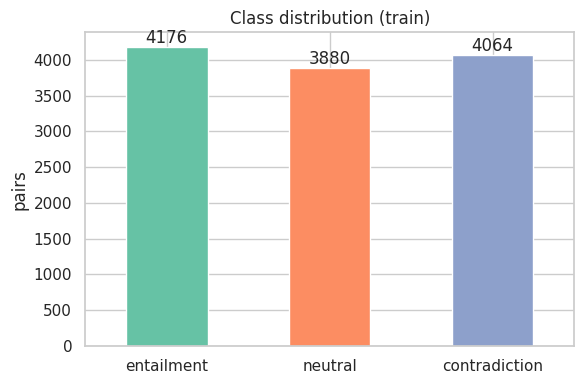

In [10]:
# Target variable: label mapping and class balance
LABELS = {0: "entailment", 1: "neutral", 2: "contradiction"}   # mapping stated on the competition data page
ORDER = list(LABELS.values())
print("label values found:", sorted(train["label"].unique()))
assert set(train["label"].unique()) <= set(LABELS)

train["label_name"] = train["label"].map(LABELS)
class_counts = train["label_name"].value_counts().reindex(ORDER)
class_table = pd.DataFrame({"count": class_counts, "share_%": (100 * class_counts / len(train)).round(2)})
display(class_table)
print("majority-class baseline accuracy:", round(class_counts.max() / len(train), 4))

ax = class_table["count"].plot.bar(color=sns.color_palette("Set2", 3), rot=0, figsize=(6, 4))
ax.set(title="Class distribution (train)", xlabel="", ylabel="pairs")
ax.bar_label(ax.containers[0])
plt.tight_layout()
plt.show()

In [11]:
# Real examples: a few English and non-English pairs per class to see what each label looks like
for label in ORDER:
    subset = train[train["label_name"] == label]
    english = subset[subset["lang_abv"] == "en"].sample(2, random_state=SEED)
    other = subset[subset["lang_abv"] != "en"].sample(1, random_state=SEED)
    print(f"===== {label.upper()} =====")
    for _, row in pd.concat([english, other]).iterrows():
        print(f"[{row['language']}] P: {row['premise']}")
        print(f"{'':>{len(row['language']) + 3}}H: {row['hypothesis']}\n")

===== ENTAILMENT =====
[English] P: And he claimed she earned $11,000 a month - or $132,000 a year - from a home quilting business she had owned for 22 years.
          H: He claimed that she had a home quilting business that made $132,000 each year.

[English] P: The state legislature provides significant bipartisan support for the legal services delivery system.
          H: State legislature gives significant bipartisan support for legal delivery.

[Greek] P: Παρόλο που σήμερα εξισώνουμε εύκολα την KSM με την Αλ Κάιντα, αυτό δεν συνέβαινε πριν από την 11η Σεπτεμβρίου.
        H: Το KSM δεν θεωρήθηκε ποτέ συνδεδεμένο με την Αλ Κάιντα πριν από τις 11 Σεπτεμβρίου.

===== NEUTRAL =====
[English] P: The first, reached from Luxor, is Esna, 54 km (33 miles) by road.
          H: The only way to get to Esna is by car.

[English] P: I found her leaning against the bannisters, deadly pale. 
          H: In addition to looking pale, she also look very weak.

[Greek] P: [ Με όλη την αμεροληψία,

In [12]:
# Data quality: missing values, empty texts, stray whitespace and line breaks
def quality_report(df, name):
    rows = {}
    for col in ["premise", "hypothesis"]:
        s = df[col].fillna("")
        rows[f"{name}.{col}"] = {
            "missing": df[col].isna().sum(),
            "empty/whitespace": s.str.strip().eq("").sum(),
            "leading/trailing spaces": (s != s.str.strip()).sum(),
            "contains newline/tab": s.str.contains(r"[\n\t\r]").sum(),
        }
    return pd.DataFrame(rows).T


display(pd.concat([quality_report(train, "train"), quality_report(test, "test")]))
print("missing values per column (train):", train.isna().sum().to_dict())
print("missing values per column (test): ", test.isna().sum().to_dict())

,missing,empty/whitespace,leading/trailing spaces,contains newline/tab
train.premise,0,0,346,0
train.hypothesis,0,0,933,0
test.premise,0,0,142,0
test.hypothesis,0,0,378,0


missing values per column (train): {'id': 0, 'premise': 0, 'hypothesis': 0, 'lang_abv': 0, 'language': 0, 'label': 0, 'label_name': 0}
missing values per column (test):  {'id': 0, 'premise': 0, 'hypothesis': 0, 'lang_abv': 0, 'language': 0}


,train_n,test_n,train_%,test_%
language,,,,
English,6870,2945,56.68,56.69
Chinese,411,151,3.39,2.91
Arabic,401,159,3.31,3.06
French,390,157,3.22,3.02
Swahili,385,172,3.18,3.31
Urdu,381,168,3.14,3.23
Vietnamese,379,145,3.13,2.79
Russian,376,172,3.10,3.31
Hindi,374,150,3.09,2.89


languages in train: 15 | in test: 15
languages only in test: none


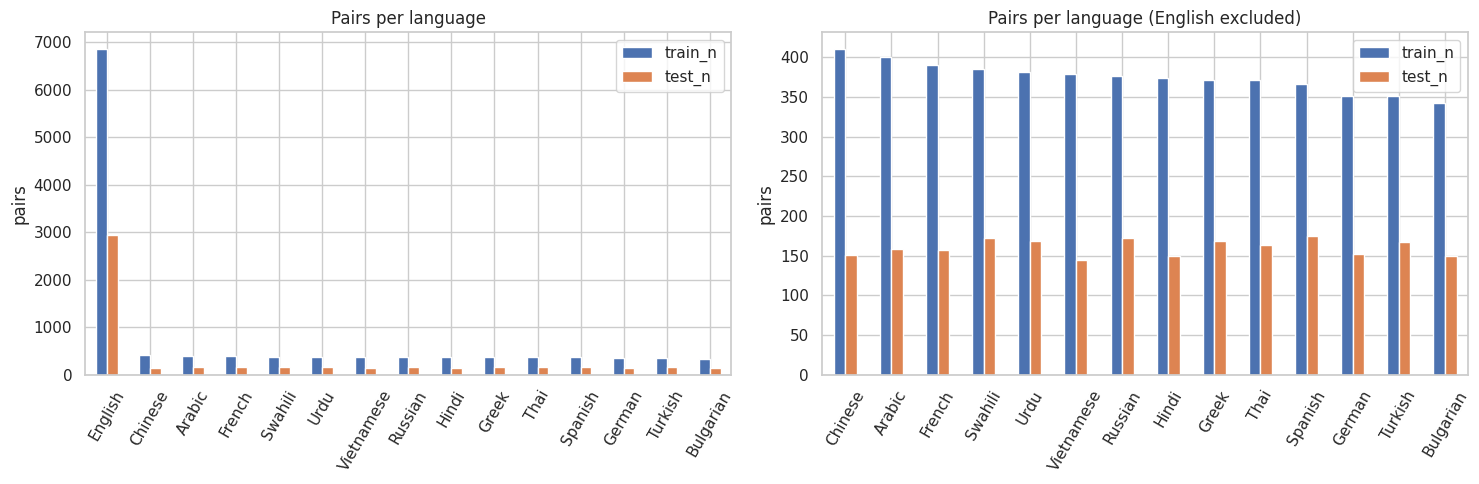

In [13]:
# Language coverage: frequencies in train vs test and consistency between the code and name columns
assert train.groupby("lang_abv")["language"].nunique().max() == 1   # each code maps to a single language name

lang_table = pd.DataFrame({
    "train_n": train["language"].value_counts(),
    "test_n": test["language"].value_counts(),
}).fillna(0).astype(int)
lang_table["train_%"] = (100 * lang_table["train_n"] / len(train)).round(2)
lang_table["test_%"] = (100 * lang_table["test_n"] / len(test)).round(2)
lang_table = lang_table.sort_values("train_n", ascending=False)
LANG_ORDER = list(lang_table.index)
display(lang_table)
print("languages in train:", train["language"].nunique(), "| in test:", test["language"].nunique())
print("languages only in test:", sorted(set(test["language"]) - set(train["language"])) or "none")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
lang_table[["train_n", "test_n"]].plot.bar(ax=axes[0], rot=60)
axes[0].set(title="Pairs per language", xlabel="", ylabel="pairs")
lang_table.drop(index="English", errors="ignore")[["train_n", "test_n"]].plot.bar(ax=axes[1], rot=60)
axes[1].set(title="Pairs per language (English excluded)", xlabel="", ylabel="pairs")
plt.tight_layout()
plt.show()

label_name,entailment,neutral,contradiction,n
language,,,,
English,35.3,31.5,33.1,6870
Chinese,34.1,35.5,30.4,411
Arabic,30.9,32.2,36.9,401
French,34.1,33.1,32.8,390
Swahili,36.4,28.3,35.3,385
Urdu,34.9,28.9,36.2,381
Vietnamese,32.2,39.3,28.5,379
Russian,35.1,33.0,31.9,376
Hindi,33.4,29.9,36.6,374


chi-square test of independence language x label: chi2=33.1, dof=28, p=0.231


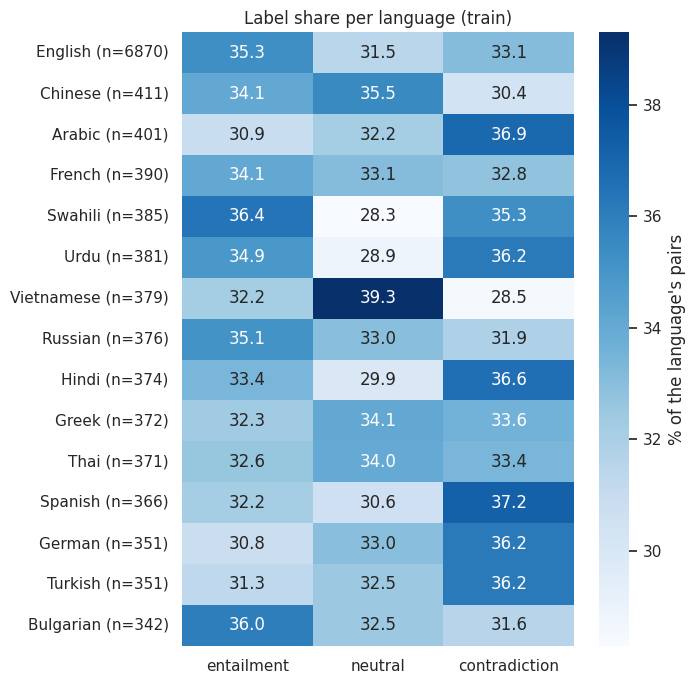

In [14]:
# Class balance inside each language: is any language skewed towards one label?
ct = pd.crosstab(train["language"], train["label_name"])[ORDER].loc[LANG_ORDER]
ct_pct = (100 * ct.div(ct.sum(axis=1), axis=0)).round(1)
ct_pct["n"] = ct.sum(axis=1)
display(ct_pct)

chi2, p_value, dof, _ = chi2_contingency(ct)
print(f"chi-square test of independence language x label: chi2={chi2:.1f}, dof={dof}, p={p_value:.3g}")

plt.figure(figsize=(7, 7))
sns.heatmap(ct_pct[ORDER], annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of the language's pairs"})
plt.yticks(np.arange(len(ct_pct)) + 0.5, [f"{lang} (n={n})" for lang, n in ct_pct["n"].items()], rotation=0)
plt.title("Label share per language (train)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

In [15]:
# Exact duplicates: repeated pairs, conflicting labels, and texts shared between train and test
PAIR = ["premise", "hypothesis"]
dup_mask = train.duplicated(PAIR, keep=False)
print("train rows whose (premise, hypothesis) pair occurs more than once:", dup_mask.sum())
conflicts = train[dup_mask].groupby(PAIR)["label"].nunique()
print("duplicated pairs with conflicting labels:", (conflicts > 1).sum())
if dup_mask.any():
    display(train.loc[dup_mask, PAIR + ["label_name", "language"]].sort_values(PAIR).head(10))

print("duplicated hypotheses in train:", train["hypothesis"].duplicated().sum())
print("duplicated pairs in test:", test.duplicated(PAIR).sum())

train_pairs = set(zip(train["premise"], train["hypothesis"]))
overlap = {
    "pair": sum((p, h) in train_pairs for p, h in zip(test["premise"], test["hypothesis"])),
    "premise": test["premise"].isin(set(train["premise"])).sum(),
    "hypothesis": test["hypothesis"].isin(set(train["hypothesis"])).sum(),
}
for unit, n in overlap.items():
    print(f"test rows whose {unit} also appears in train: {n} ({100 * n / len(test):.1f}%)")

train rows whose (premise, hypothesis) pair occurs more than once: 0
duplicated pairs with conflicting labels: 0
duplicated hypotheses in train: 1
duplicated pairs in test: 0
test rows whose pair also appears in train: 0 (0.0%)
test rows whose premise also appears in train: 2868 (55.2%)
test rows whose hypothesis also appears in train: 0 (0.0%)


In [16]:
# Near-duplicates: compare texts after Unicode normalization, lowercasing and removing punctuation
def normalize(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()
    # replace punctuation (P*) and symbols (S*) only, so combining marks in Hindi, Thai or Arabic stay intact
    text = "".join(" " if unicodedata.category(ch)[0] in "PS" else ch for ch in text)
    return " ".join(text.split())


for df in (train, test):
    df["premise_norm"] = df["premise"].map(normalize)
    df["hypothesis_norm"] = df["hypothesis"].map(normalize)

NORM_PAIR = ["premise_norm", "hypothesis_norm"]
print("unique premises, raw -> normalized:", train["premise"].nunique(), "->", train["premise_norm"].nunique())
print("extra duplicate pairs found only after normalization:",
      train.duplicated(NORM_PAIR).sum() - train.duplicated(PAIR).sum())
norm_conflicts = train[train.duplicated(NORM_PAIR, keep=False)].groupby(NORM_PAIR)["label"].nunique()
print("normalized duplicate pairs with conflicting labels:", (norm_conflicts > 1).sum())
print("test premises matching a train premise after normalization:",
      test["premise_norm"].isin(set(train["premise_norm"])).sum())

unique premises, raw -> normalized: 8209 -> 8209
extra duplicate pairs found only after normalization: 0
normalized duplicate pairs with conflicting labels: 0
test premises matching a train premise after normalization: 2868


rows: 12120 | unique premises: 8209
premises used more than once: 2800, covering 6711 rows (55.4%)


hypotheses per premise,1,2,3
premises,5409,1689,1111


distinct labels inside repeated-premise groups: {1: 131, 2: 1803, 3: 866}


,premise,hypothesis,label_name,language
47,"""So your girl writes that your little farewell activity didn't fare so well, eh?"" he chortled.",Your farewell activity didn't go well.,entailment,English
2699,"""So your girl writes that your little farewell activity didn't fare so well, eh?"" he chortled.",Your little girl wrote about how well your farewell activity went.,contradiction,English
10877,"""So your girl writes that your little farewell activity didn't fare so well, eh?"" he chortled.",Your girl wrote that your farewell activity didn't go well.,entailment,English


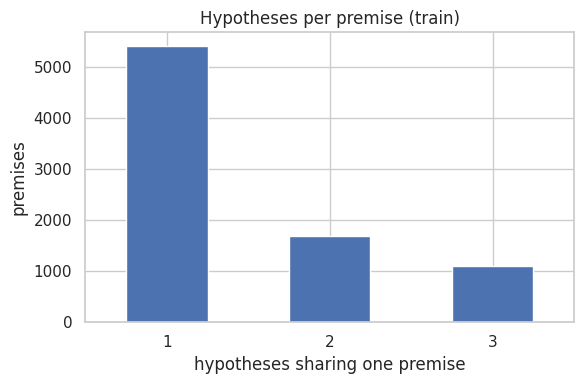

In [17]:
# Repeated premises: how many hypotheses share a premise and how labels mix inside those groups
group_sizes = train.groupby("premise").size()
repeated = group_sizes[group_sizes > 1]
print("rows:", len(train), "| unique premises:", len(group_sizes))
print(f"premises used more than once: {len(repeated)}, covering {repeated.sum()} rows ({100 * repeated.sum() / len(train):.1f}%)")
display(group_sizes.value_counts().sort_index().rename_axis("hypotheses per premise").to_frame("premises").T)

labels_per_group = train[train["premise"].isin(repeated.index)].groupby("premise")["label"].nunique()
print("distinct labels inside repeated-premise groups:", labels_per_group.value_counts().sort_index().to_dict())

# the most reused premise, to see how its hypotheses differ
display(train.loc[train["premise"] == group_sizes.idxmax(), ["premise", "hypothesis", "label_name", "language"]])

fig, ax = plt.subplots(figsize=(6, 4))
group_sizes.value_counts().sort_index().plot.bar(ax=ax, rot=0)
ax.set(title="Hypotheses per premise (train)", xlabel="hypotheses sharing one premise", ylabel="premises")
plt.tight_layout()
plt.show()

In [18]:
# Text lengths: characters for every language, whitespace-separated words only where spaces separate words
NO_SPACE_LANGS = {"zh", "th"}   # Chinese and Thai do not put spaces between words (Vietnamese spaces separate syllables)

for df in (train, test):
    for col in ["premise", "hypothesis"]:
        df[f"{col}_chars"] = df[col].str.len()
        df[f"{col}_words"] = df[col].str.split().str.len().where(~df["lang_abv"].isin(NO_SPACE_LANGS))
    df["len_ratio"] = df["hypothesis_chars"] / df["premise_chars"]

LEN_COLS = ["premise_chars", "hypothesis_chars", "premise_words", "hypothesis_words", "len_ratio"]
print("median lengths per class:")
display(train.groupby("label_name")[LEN_COLS].median().loc[ORDER].round(2))
print("summary statistics, train vs test:")
display(pd.concat({"train": train[LEN_COLS].describe().T, "test": test[LEN_COLS].describe().T}).round(1))
print("median character length per language:")
display(train.groupby("language")[["premise_chars", "hypothesis_chars"]].median().loc[LANG_ORDER].T)

median lengths per class:


,premise_chars,hypothesis_chars,premise_words,hypothesis_words,len_ratio
label_name,,,,,
entailment,96.0,49.0,17.0,9.0,0.56
neutral,95.0,55.0,17.0,10.0,0.60
contradiction,96.0,48.0,17.0,9.0,0.54


summary statistics, train vs test:


count   mean   std  min   25%   50%    75%    max
train premise_chars     12120.0  107.4  71.1  4.0  55.0  96.0  146.0  967.0
      hypothesis_chars  12120.0   53.9  25.3  4.0  36.0  51.0   67.0  276.0
      premise_words     11338.0   19.1  12.6  1.0  10.0  17.0   25.0  196.0
      hypothesis_words  11338.0    9.7   4.3  1.0   7.0   9.0   12.0   46.0
      len_ratio         12120.0    0.7   0.5  0.0   0.4   0.6    0.8    9.1
test  premise_chars      5195.0  107.6  68.7  6.0  56.0  96.0  147.0  892.0
      hypothesis_chars   5195.0   54.0  24.6  5.0  36.0  51.0   68.0  201.0
      premise_words      4880.0   19.0  12.1  1.0  10.0  17.0   25.0  194.0
      hypothesis_words   4880.0    9.7   4.2  1.0   7.0   9.0   12.0   35.0
      len_ratio          5195.0    0.7   0.5  0.0   0.4   0.6    0.9    5.3

median character length per language:


language,English,Chinese,Arabic,French,Swahili,Urdu,Vietnamese,Russian,Hindi,Greek,Thai,Spanish,German,Turkish,Bulgarian
premise_chars,95.0,32.0,83.0,113.5,96.0,99.0,109.0,104.5,100.0,115.5,90.0,114.0,111.0,97.0,108.5
hypothesis_chars,53.0,15.0,40.0,57.0,49.0,47.0,52.0,50.0,51.5,56.0,43.0,53.0,56.0,49.0,53.0


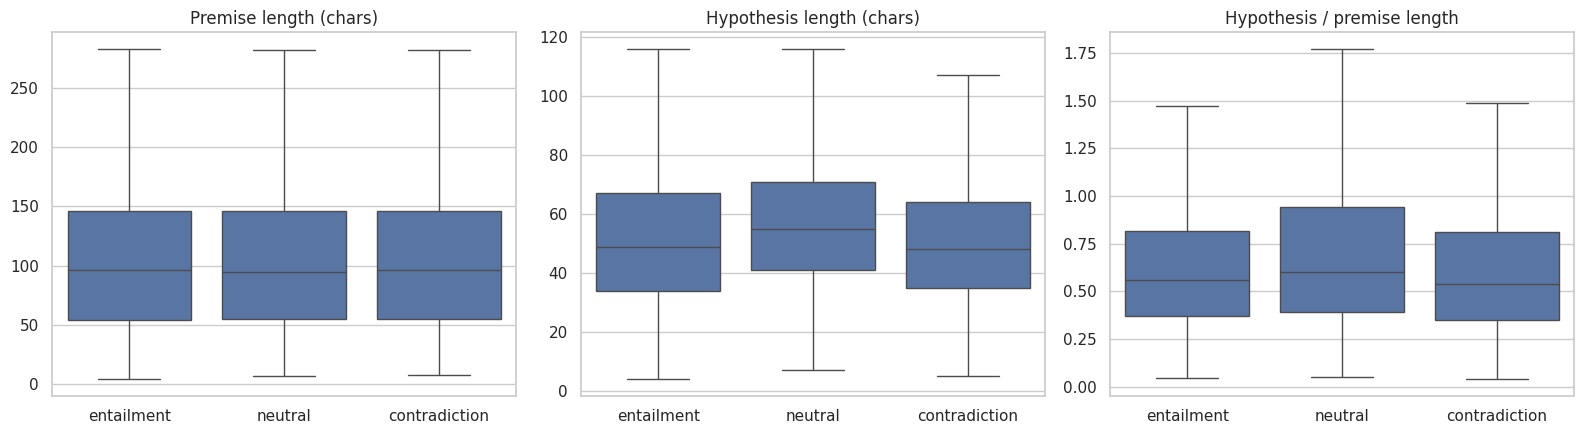

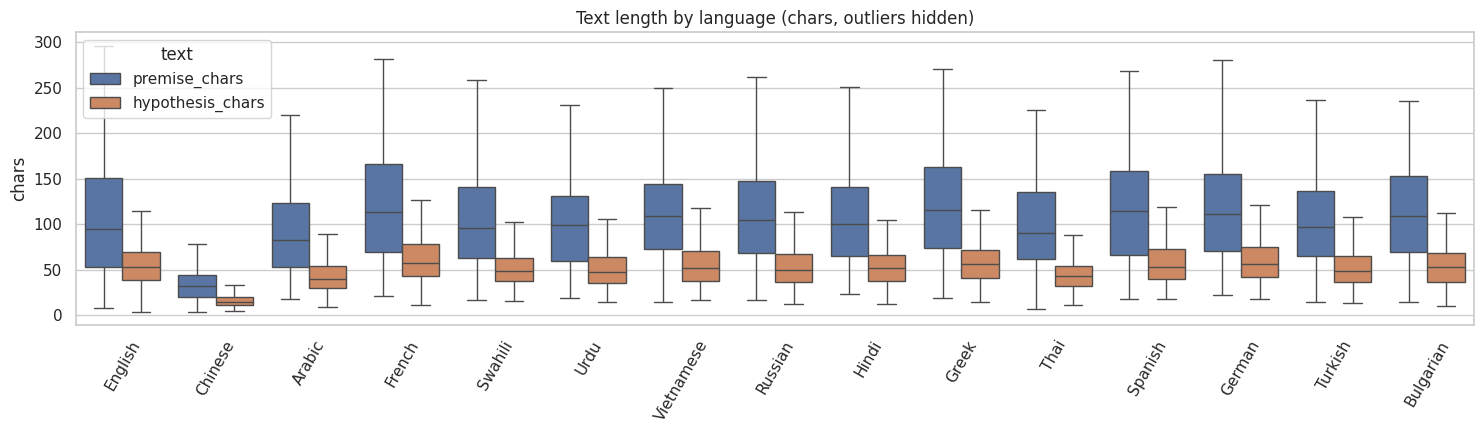

In [19]:
# Length distributions per class and per language
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col, title in zip(axes, ["premise_chars", "hypothesis_chars", "len_ratio"],
                          ["Premise length (chars)", "Hypothesis length (chars)", "Hypothesis / premise length"]):
    sns.boxplot(data=train, x="label_name", y=col, order=ORDER, ax=ax, showfliers=False)
    ax.set(title=title, xlabel="", ylabel="")
plt.tight_layout()
plt.show()

long_lengths = train.melt(id_vars="language", value_vars=["premise_chars", "hypothesis_chars"], var_name="text", value_name="chars")
fig, ax = plt.subplots(figsize=(15, 4.5))
sns.boxplot(data=long_lengths, x="language", y="chars", hue="text", order=LANG_ORDER, ax=ax, showfliers=False)
ax.set(title="Text length by language (chars, outliers hidden)", xlabel="")
ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

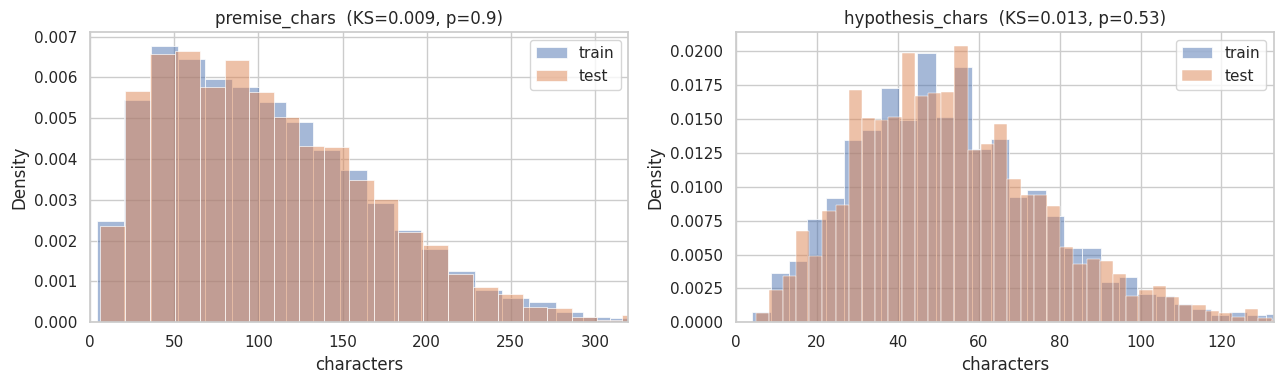

In [20]:
# Train vs test: do the test texts come from the same length distribution as the training texts?
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, ["premise_chars", "hypothesis_chars"]):
    stat, p = ks_2samp(train[col], test[col])
    sns.histplot(train[col], ax=ax, stat="density", bins=60, label="train", alpha=0.5)
    sns.histplot(test[col], ax=ax, stat="density", bins=60, label="test", alpha=0.5)
    ax.set(title=f"{col}  (KS={stat:.3f}, p={p:.2g})", xlabel="characters", xlim=(0, train[col].quantile(0.99)))
    ax.legend()
plt.tight_layout()
plt.show()

jaccard        hyp_coverage        hyp_new_units       
                 mean median         mean median          mean median
label_name                                                           
entailment      0.262  0.226        0.521  0.523         4.410    4.0
neutral         0.174  0.138        0.352  0.333         6.774    6.0
contradiction   0.189  0.152        0.402  0.385         5.532    5.0

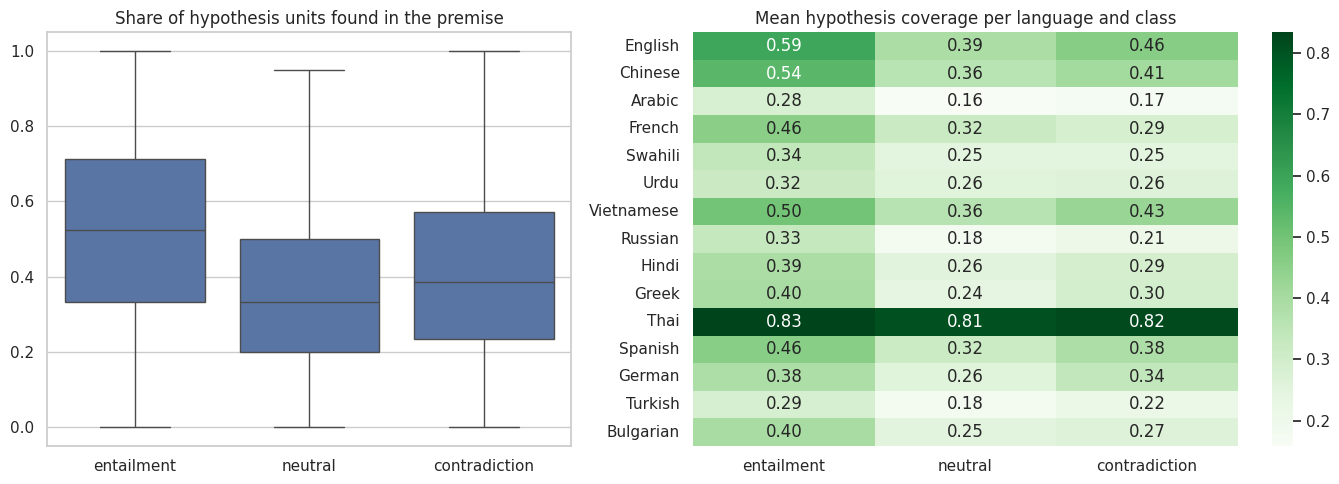

In [21]:
# Lexical overlap between premise and hypothesis: the pair relationship that NLI depends on
def units(text, lang):
    norm = normalize(text)
    if lang in NO_SPACE_LANGS:
        return set(norm.replace(" ", ""))   # single characters as units where words are not space-separated
    return set(norm.split())


def overlap_features(premise, hypothesis, lang):
    p, h = units(premise, lang), units(hypothesis, lang)
    shared, union = len(p & h), len(p | h)
    return (shared / union if union else 0.0,   # Jaccard similarity
            shared / len(h) if h else 0.0,       # share of hypothesis units that appear in the premise
            len(h - p))                          # hypothesis units absent from the premise


OVERLAP_COLS = ["jaccard", "hyp_coverage", "hyp_new_units"]
train[OVERLAP_COLS] = [overlap_features(p, h, l) for p, h, l in zip(train["premise"], train["hypothesis"], train["lang_abv"])]
display(train.groupby("label_name")[OVERLAP_COLS].agg(["mean", "median"]).loc[ORDER].round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1, 1.3]})
sns.boxplot(data=train, x="label_name", y="hyp_coverage", order=ORDER, ax=axes[0], showfliers=False)
axes[0].set(title="Share of hypothesis units found in the premise", xlabel="", ylabel="")
coverage_by_lang = train.pivot_table(index="language", columns="label_name", values="hyp_coverage", aggfunc="mean")[ORDER].loc[LANG_ORDER]
sns.heatmap(coverage_by_lang, annot=True, fmt=".2f", cmap="Greens", ax=axes[1])
axes[1].set(title="Mean hypothesis coverage per language and class", xlabel="", ylabel="")
plt.tight_layout()
plt.show()

% of pairs with each negation cue, per class:


,prem_neg,hyp_neg,neg_only_in_hyp
label_name,,,
entailment,19.2,14.0,4.9
neutral,19.1,14.0,8.1
contradiction,19.4,38.9,32.9


label distribution (%) when the negation appears only in the hypothesis vs otherwise:


label_name,entailment,neutral,contradiction
neg_only_in_hyp,,,
False,38.7,34.7,26.6
True,11.1,16.9,72.1


% of hypotheses with negation per language and class:


label_name,entailment,neutral,contradiction
language,,,
English,14.5,14.9,38.4
Chinese,15.0,14.4,52.0
Arabic,16.1,15.5,45.3
French,15.8,18.6,46.9
Swahili,2.9,1.8,9.6
Urdu,14.3,15.5,38.4
Vietnamese,9.0,14.1,50.9
Russian,19.7,12.9,40.8
Hindi,10.4,11.6,35.8


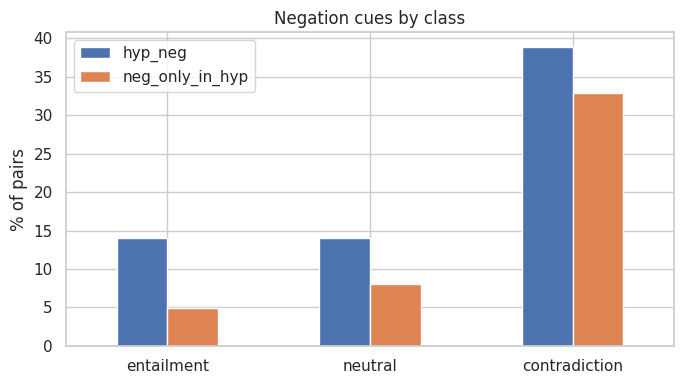

In [22]:
# Negation cues: a small multilingual lexicon to test whether negation in the hypothesis signals contradiction
# Rough lexicon: Turkish and Swahili also negate through verb affixes, and Arabic particles can attach to other words, so recall is lower there
NEGATION = {
    "en": {"not", "no", "never", "nobody", "nothing", "none", "neither", "nor", "cannot", "without", "nowhere"},
    "fr": {"ne", "n", "pas", "jamais", "rien", "aucun", "aucune", "sans", "ni"},
    "es": {"no", "nunca", "jamás", "nada", "nadie", "ningún", "ninguno", "ninguna", "sin", "tampoco", "ni"},
    "de": {"nicht", "kein", "keine", "keinen", "keinem", "keiner", "nie", "niemals", "nichts", "niemand", "ohne", "weder"},
    "ru": {"не", "нет", "никогда", "ничего", "никто", "ни", "без"},
    "bg": {"не", "няма", "никога", "нищо", "никой", "без"},
    "el": {"δεν", "μην", "μη", "ποτέ", "τίποτα", "κανένας", "κανείς", "καμία", "χωρίς"},
    "tr": {"değil", "yok", "hiç", "hiçbir", "asla"},
    "ar": {"لا", "لم", "لن", "ليس", "ليست", "غير", "بدون", "أبدا"},
    "hi": {"नहीं", "न", "मत", "बिना"},
    "ur": {"نہیں", "نہ", "مت", "بغیر"},
    "sw": {"si", "sio", "siyo", "hakuna", "bila", "hapana"},
    "vi": {"không", "chẳng", "chưa", "đừng", "chả"},
    "zh": {"不", "没", "沒", "无", "無", "未", "别", "別"},
    "th": {"ไม่"},
}


def has_negation(text, lang):
    norm = normalize(text)
    if lang in NO_SPACE_LANGS:
        return any(cue in norm for cue in NEGATION[lang])   # substring match without word boundaries
    if lang == "en" and re.search(r"n['’]t\b", str(text).lower()):
        return True   # contractions such as "isn't", lost by normalize() because it removes the apostrophe
    return bool(set(norm.split()) & NEGATION.get(lang, set()))


train["prem_neg"] = [has_negation(t, l) for t, l in zip(train["premise"], train["lang_abv"])]
train["hyp_neg"] = [has_negation(t, l) for t, l in zip(train["hypothesis"], train["lang_abv"])]
train["neg_only_in_hyp"] = train["hyp_neg"] & ~train["prem_neg"]

NEG_COLS = ["prem_neg", "hyp_neg", "neg_only_in_hyp"]
print("% of pairs with each negation cue, per class:")
display((100 * train.groupby("label_name")[NEG_COLS].mean()).loc[ORDER].round(1))
print("label distribution (%) when the negation appears only in the hypothesis vs otherwise:")
display((100 * pd.crosstab(train["neg_only_in_hyp"], train["label_name"], normalize="index"))[ORDER].round(1))
print("% of hypotheses with negation per language and class:")
display((100 * train.pivot_table(index="language", columns="label_name", values="hyp_neg", aggfunc="mean"))[ORDER].loc[LANG_ORDER].round(1))

ax = (100 * train.groupby("label_name")[["hyp_neg", "neg_only_in_hyp"]].mean()).loc[ORDER].plot.bar(rot=0, figsize=(7, 4))
ax.set(title="Negation cues by class", xlabel="", ylabel="% of pairs")
plt.tight_layout()
plt.show()

In [23]:
# Numbers: hypotheses mentioning a number that the premise does not contain (motivates NER/POS-based features)
def numbers(text):
    return set(re.findall(r"\d+(?:[.,]\d+)?", str(text)))   # \d also matches Arabic-Indic and Devanagari digits


train["hyp_has_number"] = train["hypothesis"].map(lambda t: bool(numbers(t)))
train["hyp_new_number"] = [bool(numbers(h) - numbers(p)) for p, h in zip(train["premise"], train["hypothesis"])]
num_table = train.groupby("label_name")[["hyp_has_number", "hyp_new_number"]].agg(["sum", "mean"]).loc[ORDER]
num_table.loc[:, (slice(None), "mean")] *= 100   # convert the shares to percentages
display(num_table.round(2))

hyp_has_number       hyp_new_number      
                         sum  mean            sum  mean
label_name                                             
entailment               261  6.25             65  1.56
neutral                  332  8.56            254  6.55
contradiction            219  5.39            141  3.47

In [24]:
# Hypothesis-only cues (English): words whose presence in the hypothesis is most associated with each class
MIN_DOCS = 20   # ignore rare words, their ratios are unreliable
en = train[train["lang_abv"] == "en"]
doc_freq = {label: Counter(w for t in en.loc[en["label_name"] == label, "hypothesis"] for w in set(normalize(t).split())) for label in ORDER}
vocab = [w for w in set().union(*doc_freq.values()) if sum(c[w] for c in doc_freq.values()) >= MIN_DOCS]

rows = []
for label in ORDER:
    n_in = (en["label_name"] == label).sum()
    n_out = len(en) - n_in
    for w in vocab:
        in_class = doc_freq[label][w]
        out_class = sum(doc_freq[o][w] for o in ORDER if o != label)
        log_ratio = np.log2(((in_class + 1) / (n_in + 2)) / ((out_class + 1) / (n_out + 2)))   # add-one smoothed
        rows.append((label, w, in_class, out_class, round(log_ratio, 2)))

cue_words = pd.DataFrame(rows, columns=["class", "word", "hyps_in_class", "hyps_other_classes", "log2_ratio"])
top_cues = cue_words.sort_values("log2_ratio", ascending=False).groupby("class").head(10)
for label in ORDER:
    print(f"--- top hypothesis words for {label} ---")
    display(top_cues[top_cues["class"] == label].drop(columns="class").reset_index(drop=True).T)

--- top hypothesis words for entailment ---


,0,1,2,3,4,5,6,7,8,9
word,something,located,face,certain,home,music,national,dollars,standards,congress
hyps_in_class,27,17,13,13,19,11,17,11,12,10
hyps_other_classes,18,12,10,10,15,9,14,10,11,10
log2_ratio,1.43,1.34,1.22,1.22,1.19,1.13,1.13,1.0,0.99,0.87


--- top hypothesis words for neutral ---


,0,1,2,3,4,5,6,7,8,9
word,because,order,also,hours,better,help,1,due,needs,coming
hyps_in_class,94,13,29,12,27,28,12,17,14,11
hyps_other_classes,57,8,19,8,19,21,9,13,11,9
log2_ratio,1.83,1.76,1.7,1.65,1.6,1.52,1.5,1.48,1.44,1.38


--- top hypothesis words for contradiction ---


,0,1,2,3,4,5,6,7,8,9
word,never,nothing,no,anything,completely,any,ever,everything,definitely,anyone
hyps_in_class,110,44,213,40,18,81,20,16,12,12
hyps_other_classes,30,12,80,16,8,44,11,9,8,8
log2_ratio,2.85,2.8,2.41,2.28,2.09,1.88,1.82,1.78,1.54,1.54


In [25]:
# EDA summary: key numbers behind the preprocessing and validation decisions
summary = {
    "train rows": len(train),
    "test rows": len(test),
    "languages": train["language"].nunique(),
    "English share of train (%)": round(100 * (train["lang_abv"] == "en").mean(), 1),
    "smallest language in train": f"{lang_table['train_n'].idxmin()} ({lang_table['train_n'].min()} rows)",
    "class shares (%)": (100 * class_counts / len(train)).round(1).to_dict(),
    "missing texts (train+test)": int(train[PAIR].isna().sum().sum() + test[PAIR].isna().sum().sum()),
    "exact duplicate pairs in train": int(train.duplicated(PAIR).sum()),
    "duplicate pairs with conflicting labels": int((conflicts > 1).sum()),
    "rows sharing a premise with another row (%)": round(100 * repeated.sum() / len(train), 1),
    "test rows whose premise is in train (%)": round(100 * overlap["premise"] / len(test), 1),
    "median hyp coverage by class": train.groupby("label_name")["hyp_coverage"].median().loc[ORDER].round(2).to_dict(),
    "hyp negation by class (%)": (100 * train.groupby("label_name")["hyp_neg"].mean()).loc[ORDER].round(1).to_dict(),
}
for key, value in summary.items():
    print(f"{key:<46} {value}")

# Findings on the real data and the decisions they support (applied in the preprocessing / split section):
# - 12,120 train and 5,195 test pairs, no missing or empty texts, no duplicate pairs and no conflicting labels,
#   so no rows are removed; 346 premises and 933 hypotheses have stray leading/trailing spaces, so texts are stripped.
# - Classes are nearly balanced (34.5 / 32.0 / 33.5 %, majority baseline 0.345), so accuracy and macro-F1 should be close;
#   a large gap between them would point to one class (most likely neutral) being under-predicted.
# - English is 56.7 % of train; each of the other 14 languages has only 342-411 rows (about 70-80 in a 20 % validation set),
#   so per-language results must be reported with sample counts and read with caution.
# - Language and label are independent (chi-square p = 0.23) and train/test language shares match within 0.5 points,
#   so stratifying the split by label alone keeps both distributions; language shares are still checked after splitting.
# - Only 8,209 unique premises for 12,120 rows: 55.4 % of rows share their premise with 1-2 other hypotheses, usually
#   with different labels. The split is grouped by premise so that validation measures performance on unseen premises.
#   Note: 55.2 % of test rows reuse a train premise, so this grouped validation is slightly pessimistic compared with
#   the Kaggle score; reporting validation accuracy separately for seen and unseen premises is a useful extra check.
# - Lengths do not separate the classes (median premise 95-96 chars for all; neutral hypotheses are slightly longer,
#   55 vs 48-49 chars), so length is only a weak extra feature. Chinese texts are about 3x shorter in characters,
#   and Chinese and Thai have no word spaces, so character n-grams are used alongside word n-grams.
# - Overlap is the clearest pair signal: 52 % of hypothesis units appear in the premise for entailment vs 33 % for
#   neutral and 38 % for contradiction, so overlap features (Jaccard, coverage, new units) are added to the n-grams.
# - Negation is kept, never removed as a stopword: 38.9 % of contradiction hypotheses contain a negation vs 14.0 % for
#   the other classes, and when negation appears only in the hypothesis the pair is a contradiction 72.1 % of the time.
#   The lexicon misses most Swahili and Turkish negation (verb affixes), where rates are much lower.
# - A number in the hypothesis that is absent from the premise is most common in neutral pairs (6.6 % vs 1.6 % for
#   entailment), which supports NER/number-mismatch features.
# - English hypotheses alone carry label cues ("never", "nothing", "no" -> contradiction; "because", "also" -> neutral),
#   a known annotation artifact: the hypothesis must stay distinguishable from the premise in the representation.

# Drop the EDA helper columns so later sections start from the original data
train = train[ORIGINAL_TRAIN_COLS].copy()
test = test[ORIGINAL_TEST_COLS].copy()

train rows                                     12120
test rows                                      5195
languages                                      15
English share of train (%)                     56.7
smallest language in train                     Bulgarian (342 rows)
class shares (%)                               {'entailment': 34.5, 'neutral': 32.0, 'contradiction': 33.5}
missing texts (train+test)                     0
exact duplicate pairs in train                 0
duplicate pairs with conflicting labels        0
rows sharing a premise with another row (%)    55.4
test rows whose premise is in train (%)        55.2
median hyp coverage by class                   {'entailment': 0.52, 'neutral': 0.33, 'contradiction': 0.38}
hyp negation by class (%)                      {'entailment': 14.0, 'neutral': 14.0, 'contradiction': 38.9}
